# DSCI 552 - Homework 8

- **Name:** Jesse Fulcher
- **GitHub Username:** jfulch
- **USC ID:** 7451-9585-45

## AI Use Disclosure

I used GitHub Copilot in VS Code to help with this homework.

- **Code:** Copilot help me in suggesting code and helped revise code for loading and splitting the data, training Gaussian and L1 SVMs, choosing settings with 10-fold cross-validation, using class weights, and calculating evaluation scores. It also helped make suggestions on the K-means clustering, CH score selection, and 50-run simulation code.

- **Debugging:** Copilot helped identify and fix issues with exact-match calculations, indentation, cluster membership comparisons, and a missing NumPy import.

- **Written answers:** Copilot explained the methods and explained the simplified answers using my notebook results.

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

### 1(a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set from: https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+%28Diagnostic%29. Download the data in https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data, which has IDs, classes (Benign=B, Malignant=M), and 30 attributes. This data has two output classes

In [5]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/wdbc.data")
df = pd.read_csv(data_path, header=None)

x = df.iloc[:, 2:].copy()
y = df.iloc[:, 1].copy()
y.name = "Diagnosis"

print("Full dataset shape:", df.shape)
print("Features shape:", x.shape)
print("Target shape:", y.shape)
print("Class Count:")
print(y.value_counts())
print("Total missing values:", df.isna().sum().sum())

Full dataset shape: (569, 32)
Features shape: (569, 30)
Target shape: (569,)
Class Count:
Diagnosis
B    357
M    212
Name: count, dtype: int64
Total missing values: 0


### 1(b) - Monte-Carlo Simulation: Repeat the following procedures for supervised, unsupervised, and semi-supervised learning M = 30 times, and use randomly selected train and test data (make sure you use 20% of both the positve and negative classes as the test set). Then compare the average scores (accuracy, precision, recall, F1-score, and AUC) that you obtain from each algorithm.

#### 1(b)(i) - Supervised Learning: Train an L1-penalized SVM to classify the data. Use 5 fold cross validation to choose the penalty parameter. Use normalized data. Report the average accuracy, precision, recall, F1-score, and AUC, for both training and test sets over your M runs. Plot the ROC and report the confusion matrix for training and testing in one of the runs.

In [10]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay,
)

y_binary = y.map({"B": 0, "M": 1})

M = 30
c_values = [0.001, 0.01, 0.1, 1, 10, 100]
results = []
example_run = None

for seed in range(M):
    x_train, x_test, y_train, y_test = train_test_split(
        x, 
        y_binary, 
        test_size=0.2, 
        stratify=y_binary, random_state=seed
    )

    cv = StratifiedKFold(
        n_splits=5, 
        shuffle=True,
        random_state=seed,
    )

    model = Pipeline([
        ("scaler", MinMaxScaler()),
        ("svc", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=1000000,
            random_state=seed,
        ))
    ])

    search = GridSearchCV(
        model,
        {"svc__C": c_values},
        scoring="accuracy",
        cv=cv,
        error_score="raise",
    )
    search.fit(x_train, y_train)

    for split, features, labels in [
        ("training", x_train, y_train),
        ("Test", x_test, y_test),
    ]:
        predictions = search.predict(features)
        score = search.decision_function(features)

        results.append({
            "Run": seed + 1,
            "Set": split,
            "Best C": search.best_params_["svc__C"],
            "Accuracy": accuracy_score(labels, predictions),
            "Precision": precision_score(labels, predictions, zero_division=0),
            "Recall": recall_score(labels, predictions, zero_division=0),
            "F1": f1_score(labels, predictions, zero_division=0),
            "AUC": roc_auc_score(labels, score),
        })

        if seed == 0:
            if example_run is None:
                example_run = {}

            example_run[split] = {
                "labels": labels,
                "predictions": predictions,
                "score": score,
            }

    print(
        f"Finished run {seed + 1}/{M}"
        f"Best C = {search.best_params_['svc__C']}"
    )

supervised_results = pd.DataFrame(results)

metric_columns = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
supervised_averages = (
    supervised_results.groupby("Set")[metric_columns].mean().reindex(["training", "Test"])
)

print("Average scores across 30 runs: ")
display(supervised_averages)
    

Finished run 1/30Best C = 1
Finished run 2/30Best C = 1
Finished run 3/30Best C = 1
Finished run 4/30Best C = 10
Finished run 5/30Best C = 10
Finished run 6/30Best C = 1
Finished run 7/30Best C = 10
Finished run 8/30Best C = 1
Finished run 9/30Best C = 1
Finished run 10/30Best C = 1
Finished run 11/30Best C = 1
Finished run 12/30Best C = 1
Finished run 13/30Best C = 1
Finished run 14/30Best C = 1
Finished run 15/30Best C = 1
Finished run 16/30Best C = 1
Finished run 17/30Best C = 1
Finished run 18/30Best C = 1
Finished run 19/30Best C = 1
Finished run 20/30Best C = 100
Finished run 21/30Best C = 1
Finished run 22/30Best C = 10
Finished run 23/30Best C = 1
Finished run 24/30Best C = 1
Finished run 25/30Best C = 1
Finished run 26/30Best C = 1
Finished run 27/30Best C = 10
Finished run 28/30Best C = 1
Finished run 29/30Best C = 1
Finished run 30/30Best C = 1
Average scores across 30 runs: 


,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
training,0.985788,0.990808,0.97098,0.980777,0.997470
Test,0.964620,0.970779,0.93254,0.950754,0.992471


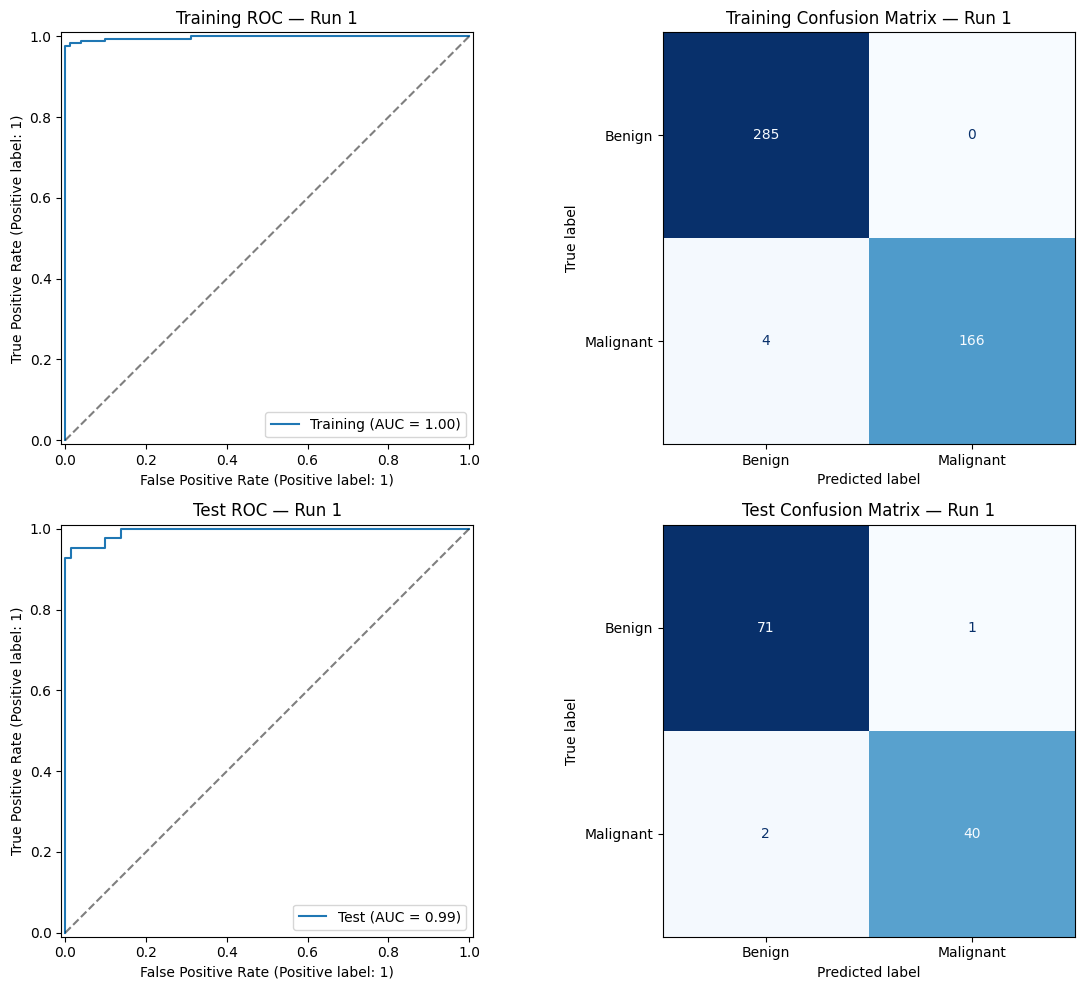

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for row, split in enumerate(["training", "Test"]):
    values = example_run[split]

    RocCurveDisplay.from_predictions(
        values["labels"],
        values["score"],
        ax=axes[row, 0],
        name=split.capitalize(),
    )
    axes[row, 0].plot([0, 1], [0, 1], "k--", alpha=0.5)
    axes[row, 0].set_title(f"{split.capitalize()} ROC — Run 1")

    ConfusionMatrixDisplay.from_predictions(
        values["labels"],
        values["predictions"],
        labels=[0, 1],
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        ax=axes[row, 1],
        colorbar=False,
    )
    axes[row, 1].set_title(
        f"{split.capitalize()} Confusion Matrix — Run 1"
    )

plt.tight_layout()
plt.show()

#### 1(b)(ii) - Semi-Supervised Learning/ Self-training: select 50% of the positive class along with 50% of the negative class in the training set as labeled data and the rest as unlabelled data. You can select them randomly.

In [14]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y_binary,
    test_size=0.20,
    stratify=y_binary,
    random_state=0,
)

x_labeled, x_unlabeled, y_labeled, y_unlabeled_hidden = train_test_split(
    x_train,
    y_train,
    train_size=0.50,
    stratify=y_train,
    random_state=0,
)

print("Training observations:", len(x_train))
print("Labeled observations:", len(x_labeled))
print("Unlabeled observations:", len(x_unlabeled))
print("Test observations:", len(x_test))
print("Labeled class counts (0 = benign, 1 = malignant):")
print(y_labeled.value_counts().sort_index())
print("Overlap between labeled and unlabeled rows:")
print(len(x_labeled.index.intersection(x_unlabeled.index)))

Training observations: 455
Labeled observations: 227
Unlabeled observations: 228
Test observations: 114
Labeled class counts (0 = benign, 1 = malignant):
Diagnosis
0    142
1     85
Name: count, dtype: int64
Overlap between labeled and unlabeled rows:
0


##### 1(b)(ii)(A) - Train an L1-penalized SVM to classify the labeled data Use normalized data. Choose the penalty parameter using 5 fold cross validation.

##### 1(b)(ii)(B) - Find the unlabeled data point that is the farthest to the decision boundaryof the SVM. Let the SVM label it (ignore its true label), and add it tothe labeled data, and retrain the SVM. Continue this process until all unlabeled data are used. Test the final SVM on the test data andthe average accuracy, precision, recall, F1-score, and AUC, for both training and test sets over your M runs. Plot the ROC and report the confusion matrix for training and testing in one of the runs.

In [15]:
semi_results = []
semi_example_run = {}

for seed in range(30):
    x_train, x_test, y_train, y_test = train_test_split(
        x,
        y_binary,
        test_size=0.20,
        stratify=y_binary,
        random_state=seed,
    )

    x_labeled, x_unlabeled, y_labeled, _ = train_test_split(
        x_train,
        y_train,
        train_size=0.50,
        stratify=y_train,
        random_state=seed,
    )

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed,
    )

    pipeline = Pipeline([
        ("scaler", MinMaxScaler()),
        ("svc", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=1000000,
            random_state=seed,
        )),
    ])

    search = GridSearchCV(
        pipeline,
        {"svc__C": c_values},
        scoring="accuracy",
        cv=cv,
        error_score="raise",
    )
    search.fit(x_labeled, y_labeled)

    model = search.best_estimator_

    while not x_unlabeled.empty:
        scores = model.decision_function(x_unlabeled)

        position = np.argmax(np.abs(scores))
        selected_index = x_unlabeled.index[position]
        selected_point = x_unlabeled.loc[[selected_index]]
        pseudo_label = int(model.predict(selected_point)[0])

        x_labeled = pd.concat([x_labeled, selected_point])
        y_labeled = pd.concat([
            y_labeled,
            pd.Series(
                [pseudo_label],
                index=[selected_index],
                name=y_labeled.name,
            ),
        ])

        x_unlabeled = x_unlabeled.drop(index=selected_index)
        model.fit(x_labeled, y_labeled)

    for split, features, labels in [
        ("Training", x_train, y_train),
        ("Test", x_test, y_test),
    ]:
        predictions = model.predict(features)
        scores = model.decision_function(features)

        semi_results.append({
            "Run": seed + 1,
            "Set": split,
            "Best C": search.best_params_["svc__C"],
            "Accuracy": accuracy_score(labels, predictions),
            "Precision": precision_score(
                labels, predictions, zero_division=0
            ),
            "Recall": recall_score(
                labels, predictions, zero_division=0
            ),
            "F1": f1_score(labels, predictions, zero_division=0),
            "AUC": roc_auc_score(labels, scores),
        })

        if seed == 0:
            semi_example_run[split] = {
                "labels": labels,
                "predictions": predictions,
                "scores": scores,
            }

    print(
        f"Finished self-training run {seed + 1}/30: "
        f"Best C = {search.best_params_['svc__C']}"
    )

semi_results = pd.DataFrame(semi_results)

metric_columns = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
semi_averages = (
    semi_results.groupby("Set")[metric_columns]
    .mean()
    .reindex(["Training", "Test"])
)

print("\nAverage self-training scores across 30 runs:")
display(semi_averages.round(4))

Finished self-training run 1/30: Best C = 1
Finished self-training run 2/30: Best C = 100
Finished self-training run 3/30: Best C = 1
Finished self-training run 4/30: Best C = 10
Finished self-training run 5/30: Best C = 1
Finished self-training run 6/30: Best C = 1
Finished self-training run 7/30: Best C = 10
Finished self-training run 8/30: Best C = 10
Finished self-training run 9/30: Best C = 1
Finished self-training run 10/30: Best C = 10
Finished self-training run 11/30: Best C = 1
Finished self-training run 12/30: Best C = 0.1
Finished self-training run 13/30: Best C = 1
Finished self-training run 14/30: Best C = 1
Finished self-training run 15/30: Best C = 1
Finished self-training run 16/30: Best C = 1
Finished self-training run 17/30: Best C = 10
Finished self-training run 18/30: Best C = 1
Finished self-training run 19/30: Best C = 1
Finished self-training run 20/30: Best C = 0.1
Finished self-training run 21/30: Best C = 1
Finished self-training run 22/30: Best C = 1
Finished

,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Training,0.9735,0.9822,0.9463,0.9636,0.9932
Test,0.9556,0.9698,0.9087,0.9371,0.9904


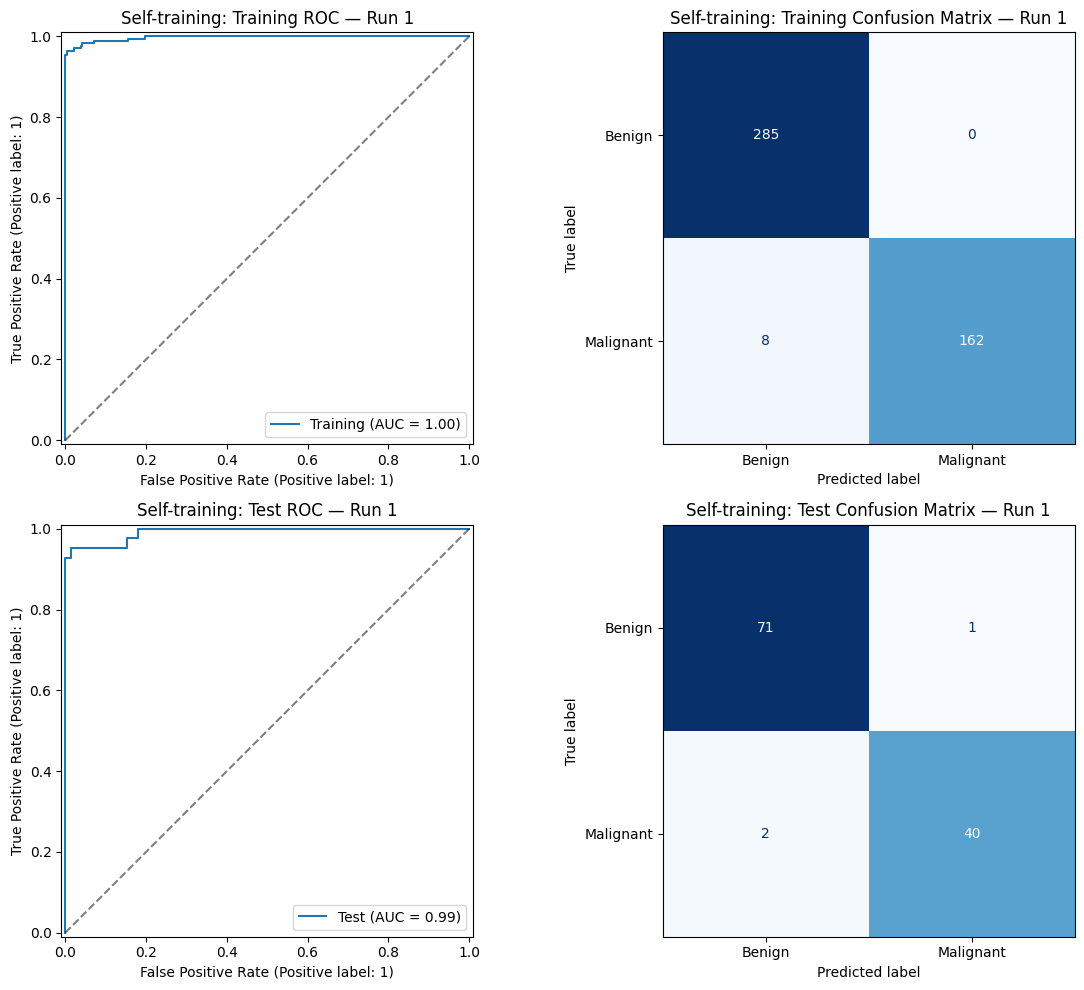

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for row, split in enumerate(["Training", "Test"]):
    values = semi_example_run[split]

    RocCurveDisplay.from_predictions(
        values["labels"],
        values["scores"],
        ax=axes[row, 0],
        name=split,
    )
    axes[row, 0].plot([0, 1], [0, 1], "k--", alpha=0.5)
    axes[row, 0].set_title(f"Self-training: {split} ROC — Run 1")

    ConfusionMatrixDisplay.from_predictions(
        values["labels"],
        values["predictions"],
        labels=[0, 1],
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        ax=axes[row, 1],
        colorbar=False,
    )
    axes[row, 1].set_title(
        f"Self-training: {split} Confusion Matrix — Run 1"
    )

plt.tight_layout()
plt.show()

#### 1(b)(iii). Unsupervised Learning: Run k-means algorithm on the whole training set. Ignore the labels of the data, and assume k = 2.

##### 1(b)(iii)(A) - Run the k-means algorithm multiple times. Make sure that you initialize the algoritm randomly. How do you make sure that the algorithm was not trapped in a local minimum?

##### 1(b)(iii)(B) - Compute the centers of the two clusters and find the closest 30 data points to each center. Read the true labels of those 30 data points and take a majority poll within them. The majority poll becomes the label predicted by k-means for the members of each cluster. Then compare the labels provided by k-means with the true labels of the training data and report the average accuracy, precision, recall, F1-score, and AUC over M runs, and ROC and the confusion matrix for one of the runs.

##### 1(b)(iii)(C) - Classify test data based on their proximity to the centers of the clusters. Report the average accuracy, precision, recall, F1-score, and AUC over M runs, and ROC and the confusion matrix for one of the runs for the test data.

In [ ]:
from sklearn.cluster import KMeans
from scipy.special import softmax
import warnings

kmeans_results = []
kmeans_example_run = {}

for seed in range(30):
    x_train, x_test, y_train, y_test = train_test_split(
        x,
        y_binary,
        test_size=0.20,
        stratify=y_binary,
        random_state=seed,
    )

    scaler = MinMaxScaler()
    train_scaled = scaler.fit_transform(x_train)
    test_scaled = scaler.transform(x_test)

    # A: Keep the lowest-inertia solution from 50 random starts.
    model = KMeans(
        n_clusters=2,
        init="random",
        n_init=50,
        random_state=seed,
    )
    model.fit(train_scaled)

    # B: Assign classes using the 30 nearest training points per center.
    train_distances = model.transform(train_scaled)
    cluster_labels = np.empty(2, dtype=int)

    for cluster in range(2):
        nearest = np.argsort(train_distances[:, cluster])[:30]
        nearest_labels = y_train.iloc[nearest].to_numpy()
        counts = np.bincount(nearest_labels, minlength=2)

        if counts[0] == counts[1]:
            warnings.warn(
                f"Run {seed + 1}, cluster {cluster}: "
                "majority vote tied; using the nearest point's label."
            )
            cluster_labels[cluster] = nearest_labels[0]
        else:
            cluster_labels[cluster] = counts.argmax()

    if np.unique(cluster_labels).size == 1:
        warnings.warn(
            f"Run {seed + 1}: both clusters received the same class."
        )

    for split, features, labels in [
        ("Training", train_scaled, y_train),
        ("Test", test_scaled, y_test),
    ]:
        distances = model.transform(features)
        predictions = cluster_labels[model.predict(features)]

        weights = softmax(-distances, axis=1)
        scores = weights @ cluster_labels

        kmeans_results.append({
            "Run": seed + 1,
            "Set": split,
            "Accuracy": accuracy_score(labels, predictions),
            "Precision": precision_score(
                labels, predictions, zero_division=0
            ),
            "Recall": recall_score(
                labels, predictions, zero_division=0
            ),
            "F1": f1_score(labels, predictions, zero_division=0),
            "AUC": roc_auc_score(labels, scores),
        })

        if seed == 0:
            kmeans_example_run[split] = {
                "labels": labels,
                "predictions": predictions,
                "scores": scores,
            }

    print(
        f"Finished k-means run {seed + 1}/30: "
        f"cluster classes = {cluster_labels.tolist()}"
    )

kmeans_results = pd.DataFrame(kmeans_results)

metric_columns = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
kmeans_averages = (
    kmeans_results.groupby("Set")[metric_columns]
    .mean()
    .reindex(["Training", "Test"])
)

print("\nAverage k-means scores across 30 runs:")
display(kmeans_averages.round(4))

Finished k-means run 1/30: cluster classes = [0, 1]
Finished k-means run 2/30: cluster classes = [0, 1]
Finished k-means run 3/30: cluster classes = [1, 0]
Finished k-means run 4/30: cluster classes = [0, 1]
Finished k-means run 5/30: cluster classes = [0, 1]
Finished k-means run 6/30: cluster classes = [1, 0]
Finished k-means run 7/30: cluster classes = [1, 0]
Finished k-means run 8/30: cluster classes = [0, 1]
Finished k-means run 9/30: cluster classes = [0, 1]
Finished k-means run 10/30: cluster classes = [0, 1]
Finished k-means run 11/30: cluster classes = [1, 0]
Finished k-means run 12/30: cluster classes = [0, 1]
Finished k-means run 13/30: cluster classes = [1, 0]
Finished k-means run 14/30: cluster classes = [0, 1]
Finished k-means run 15/30: cluster classes = [0, 1]
Finished k-means run 16/30: cluster classes = [0, 1]
Finished k-means run 17/30: cluster classes = [0, 1]
Finished k-means run 18/30: cluster classes = [1, 0]
Finished k-means run 19/30: cluster classes = [0, 1]
Fi

,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Training,0.9261,0.9514,0.8457,0.8953,0.9804
Test,0.9246,0.9410,0.8492,0.8919,0.9783


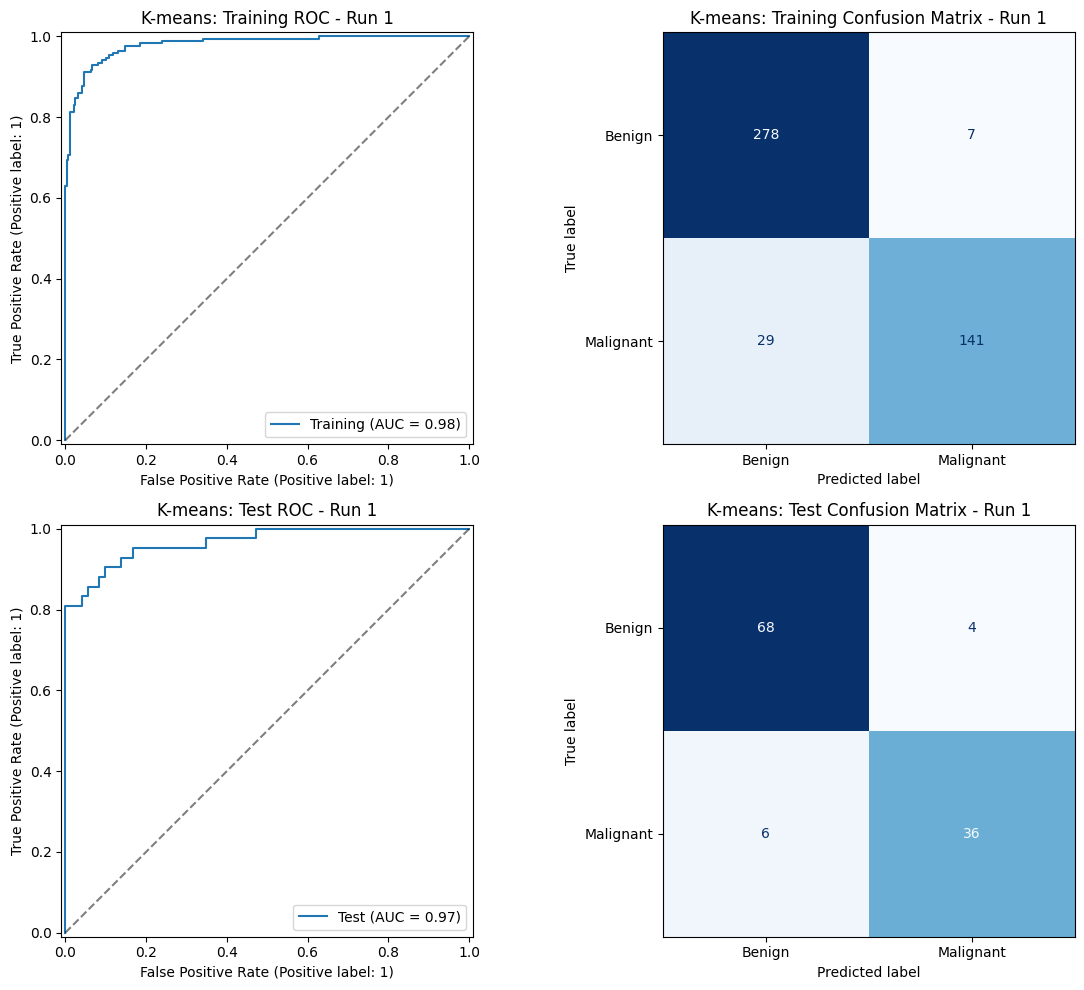

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for row, split in enumerate(["Training", "Test"]):
    values = kmeans_example_run[split]

    RocCurveDisplay.from_predictions(
        values["labels"],
        values["scores"],
        ax=axes[row, 0],
        name=split,
    )
    axes[row, 0].plot([0, 1], [0, 1], "k--", alpha=0.5)
    axes[row, 0].set_title(f"K-means: {split} ROC - Run 1")

    ConfusionMatrixDisplay.from_predictions(
        values["labels"],
        values["predictions"],
        labels=[0, 1],
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        ax=axes[row, 1],
        colorbar=False,
    )
    axes[row, 1].set_title(
        f"K-means: {split} Confusion Matrix - Run 1"
    )

plt.tight_layout()
plt.show()